<a href="https://colab.research.google.com/github/Shahin028/AIML_/blob/main/Transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix,classification_report,accuracy_score)
import pickle
print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)


All libraries imported successfully!
TensorFlow Version: 2.21.0


In [ ]:

data_dir = '/content/drive/MyDrive/ML AI ICT/Datasets/cifar-10-batches-py'

print(os.listdir(data_dir))


['test_batch', 'data_batch_3', 'data_batch_2', 'data_batch_5', 'data_batch_1', 'data_batch_4', 'batches.meta', 'readme.html']


# LOADING THE DATASET

In [ ]:
def load_batch(file_path):

    with open(file_path, 'rb') as file:
        batch = pickle.load(file, encoding='bytes')

    images = batch[b'data']
    labels = batch[b'labels']

    # Reshape images into RGB format
    images = images.reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)

    return images, np.array(labels)

# Load training batches
x_train_list = []
y_train_list = []

for i in range(1, 6):

    images, labels = load_batch(
        os.path.join(data_dir, f'data_batch_{i}')
    )

    x_train_list.append(images)
    y_train_list.append(labels)


# Combine training batches
x_train_full = np.concatenate(x_train_list)
y_train_full = np.concatenate(y_train_list)


# Load testing batch
x_test, y_test = load_batch(
    os.path.join(data_dir, 'test_batch')
)
print("Dataset loaded successfully!")
print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Dataset loaded successfully!
Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


# DEFINE CLASS NAMES

In [ ]:
class_names = [
    'Airplane',
    'Automobile',
    'Bird',
    'Cat',
    'Deer',
    'Dog',
    'Frog',
    'Horse',
    'Ship',
    'Truck'
]

print("Total classes:", len(class_names))
print(class_names)

Total classes: 10
['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']


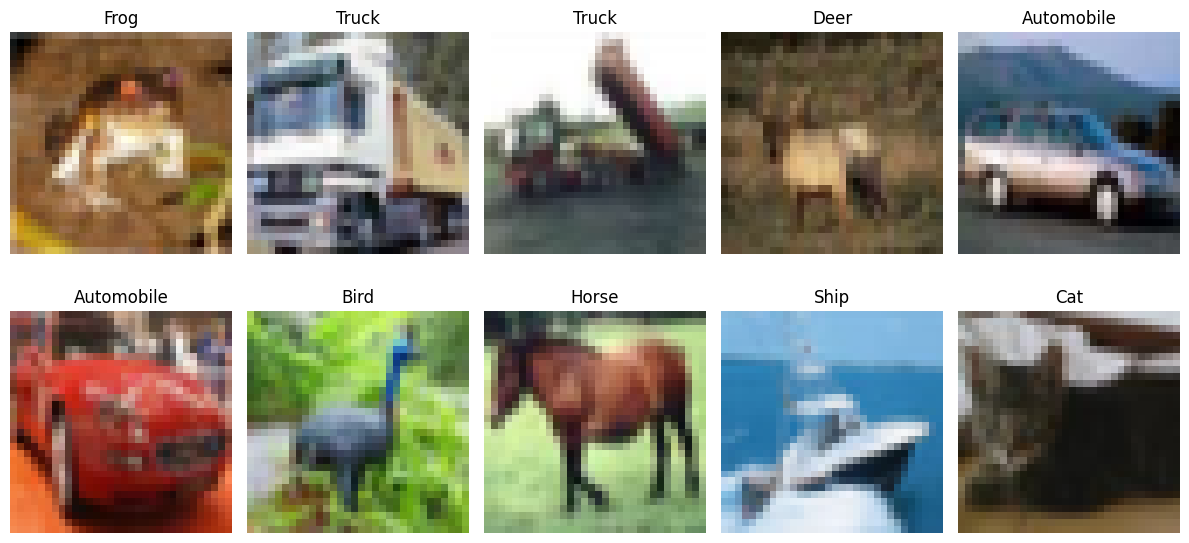

In [ ]:

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_train_full[i])

    plt.title(class_names[y_train_full[i]])

    plt.axis('off')

plt.tight_layout()
plt.show()

#SPLITING

In [ ]:

# ==========================================
# 9. TRAIN-VALIDATION SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.10,
    random_state=42,
    stratify=y_train_full
)

print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Testing images:", x_test.shape)


Training images: (45000, 32, 32, 3)
Validation images: (5000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt

# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

Device: cuda
GPU: Tesla T4


#IMAGE RESIZE, NORMALIZATION,AUNGMENTATION

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations created successfully!")

Image transformations created successfully!


#PyTorch DataLoader

In [ ]:
class CIFAR10Dataset(Dataset):

    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = Image.fromarray(self.images[index])

        if self.transform:
            image = self.transform(image)

        label = int(self.labels[index])

        return image, label

In [ ]:
train_dataset = CIFAR10Dataset(x_train, y_train, train_transform)
val_dataset = CIFAR10Dataset(x_val, y_val, test_transform)
test_dataset = CIFAR10Dataset(x_test, y_test, test_transform)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 45000
Validation dataset: 5000
Testing dataset: 10000


In [ ]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Labels: tensor([6, 6, 6, 1, 9, 1, 4, 2, 4, 0])


#LOAD PRETRAINED RESNET50

In [ ]:
weights = models.ResNet50_Weights.DEFAULT

model = models.resnet50(weights=weights)

model = model.to(device)

print("Pretrained ResNet50 loaded successfully!")
for param in model.parameters():
    param.requires_grad = False

print("ResNet50 backbone frozen successfully!")
print(model.fc)

Pretrained ResNet50 loaded successfully!
ResNet50 backbone frozen successfully!
Linear(in_features=2048, out_features=1000, bias=True)


#REPLACE CLASSIFIER

In [ ]:
num_classes = 10

model.fc = nn.Sequential(
    nn.Linear(2048, 512),
    nn.BatchNorm1d(512),
    nn.ReLU(inplace=True),
    nn.Dropout(0.5),
    nn.Linear(512, num_classes)
)

model = model.to(device)

print(model.fc)

Sequential(
  (0): Linear(in_features=2048, out_features=512, bias=True)
  (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=512, out_features=10, bias=True)
)


In [ ]:
# He initialization for hidden layer
nn.init.kaiming_normal_(
    model.fc[0].weight,
    mode='fan_in',
    nonlinearity='relu'
)

nn.init.zeros_(model.fc[0].bias)

# Xavier initialization for output layer
nn.init.xavier_uniform_(model.fc[4].weight)
nn.init.zeros_(model.fc[4].bias)

print("Weight initialization completed!")

Weight initialization completed!


##Loss function and optimizer

In [ ]:
# ==========================================
# 19. LOSS FUNCTION AND OPTIMIZER
# ==========================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Loss function and optimizer configured!")
# ==========================================
# 20. LEARNING RATE SCHEDULER
# ==========================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2
)

print("Learning rate scheduler configured!")
# ==========================================
# 21. EARLY STOPPING AND CHECKPOINT
# ==========================================

import copy

best_val_loss = float('inf')
patience = 5
early_stop_counter = 0

best_model_weights = copy.deepcopy(model.state_dict())

checkpoint_path = "best_resnet50_model.pth"

print("Early stopping and checkpoint configured!")

Loss function and optimizer configured!
Learning rate scheduler configured!
Early stopping and checkpoint configured!


##Feature Extraction Model Training and Validation

In [ ]:

# ==========================================
# 22. FEATURE EXTRACTION TRAINING
# ==========================================

import copy
import torch

num_epochs = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# Mixed Precision Training
use_amp = torch.cuda.is_available()

if use_amp:
    scaler = torch.amp.GradScaler('cuda')
else:
    scaler = None

print("Training Device:", device)
print("Mixed Precision:", use_amp)

# ==========================================
# TRAINING LOOP
# ==========================================

for epoch in range(num_epochs):

    # ---------------- TRAINING ----------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Mixed Precision Forward Pass
        with torch.autocast(
            device_type='cuda',
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        # Backpropagation
        if use_amp:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs.detach(), 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_acc = 100 * correct / total

    # ---------------- VALIDATION ----------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type='cuda',
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total

    # ---------------- SAVE HISTORY ----------------

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    # ---------------- LEARNING RATE SCHEDULER ----------------

    scheduler.step(epoch_val_loss)

    # ---------------- PRINT RESULTS ----------------

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Acc: {epoch_train_acc:.2f}% "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Acc: {epoch_val_acc:.2f}%"
    )

    # ---------------- SAVE BEST MODEL ----------------

    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss
        early_stop_counter = 0

        best_model_weights = copy.deepcopy(model.state_dict())

        torch.save(
            model.state_dict(),
            checkpoint_path
        )

        print("Best model saved!")

    else:
        early_stop_counter += 1

    # ---------------- EARLY STOPPING ----------------

    # Do not stop before completing 20 epochs
    if epoch + 1 >= 20 and early_stop_counter >= patience:

        print("Early stopping triggered!")
        break

# ==========================================
# RESTORE BEST MODEL
# ==========================================

model.load_state_dict(best_model_weights)

print("\nFeature extraction training completed!")
print("Best Validation Loss:", best_val_loss)
print("Total Epochs Completed:", len(train_losses))


Training Device: cuda
Mixed Precision: True
Epoch [1/20] Train Loss: 0.9661 Train Acc: 67.14% Val Loss: 0.5254 Val Acc: 82.24%
Best model saved!
Epoch [2/20] Train Loss: 0.7951 Train Acc: 72.59% Val Loss: 0.4823 Val Acc: 83.66%
Best model saved!
Epoch [3/20] Train Loss: 0.7612 Train Acc: 73.68% Val Loss: 0.4623 Val Acc: 84.42%
Best model saved!
Epoch [4/20] Train Loss: 0.7361 Train Acc: 74.41% Val Loss: 0.4541 Val Acc: 84.60%
Best model saved!
Epoch [5/20] Train Loss: 0.7231 Train Acc: 74.70% Val Loss: 0.4232 Val Acc: 85.26%
Best model saved!
Epoch [6/20] Train Loss: 0.7135 Train Acc: 75.34% Val Loss: 0.4471 Val Acc: 84.04%
Epoch [7/20] Train Loss: 0.7005 Train Acc: 75.57% Val Loss: 0.4390 Val Acc: 84.72%
Epoch [8/20] Train Loss: 0.6854 Train Acc: 76.06% Val Loss: 0.4467 Val Acc: 84.78%
Epoch [9/20] Train Loss: 0.6662 Train Acc: 76.91% Val Loss: 0.4058 Val Acc: 86.26%
Best model saved!
Epoch [10/20] Train Loss: 0.6471 Train Acc: 77.52% Val Loss: 0.4321 Val Acc: 84.92%
Epoch [11/20] Tra

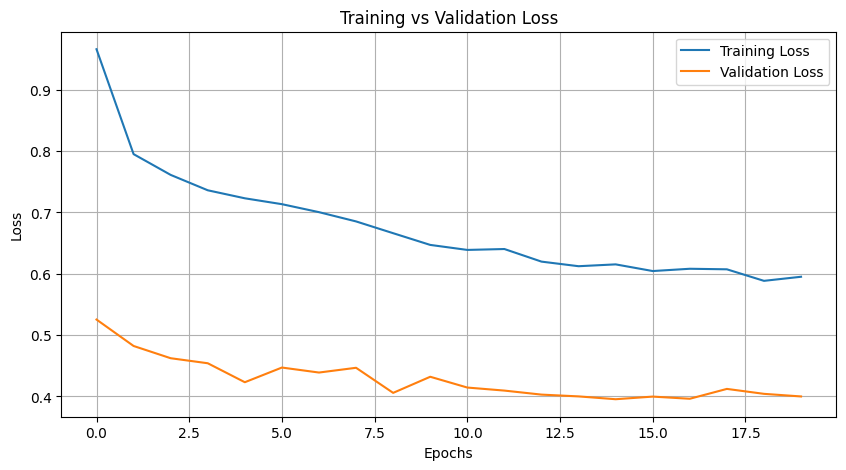

In [ ]:
# ==========================================
# 23. TRAINING VS VALIDATION LOSS
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.show()

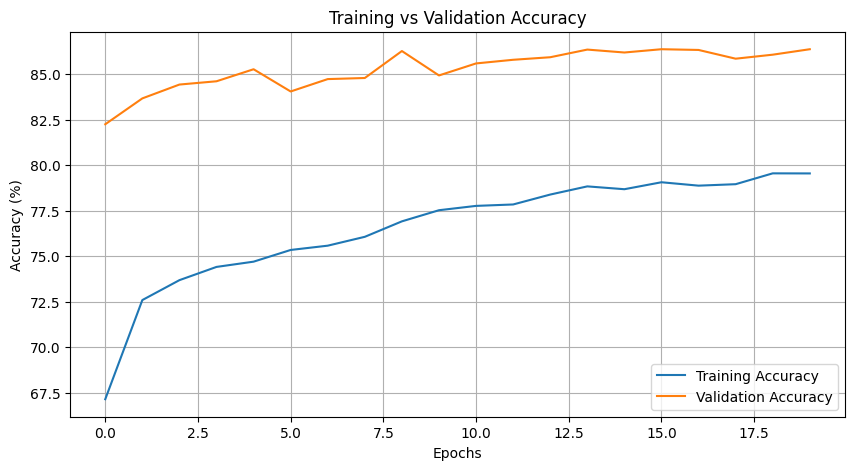

In [ ]:
# ==========================================
# 24. TRAINING VS VALIDATION ACCURACY
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ==========================================
# 25. UNFREEZE LAST RESNET50 BLOCK
# ==========================================

# Freeze all layers first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the last convolutional block
for param in model.layer4.parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in model.fc.parameters():
    param.requires_grad = True

print("Last ResNet50 block and classifier unfrozen!")

Last ResNet50 block and classifier unfrozen!


##Fine Tuning

In [ ]:
# ==========================================
# 26. FINE-TUNING OPTIMIZER
# ==========================================

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5,
    weight_decay=0.0001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2
)

print("Fine-tuning optimizer configured!")
feature_extraction_best_acc = max(val_accuracies)

print(
    "Feature extraction best validation accuracy:",
    round(feature_extraction_best_acc, 2), "%"
)

Fine-tuning optimizer configured!
Feature extraction best validation accuracy: 86.36 %


##Feature Extraction Training with Mixed Precision and Early Stopping

In [ ]:
# ==========================================
# 27. FINE-TUNING TRAINING
# ==========================================

num_epochs_finetune = 15

finetune_train_losses = []
finetune_val_losses = []

finetune_train_accuracies = []
finetune_val_accuracies = []

best_finetune_val_loss = float('inf')
early_stop_counter = 0
patience = 5

finetune_checkpoint = "best_resnet50_finetuned.pth"

for epoch in range(num_epochs_finetune):

    # ---------------- TRAINING ----------------
    model.train()

    # Keep frozen backbone BatchNorm statistics unchanged
    model.bn1.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_acc = 100 * correct / total

    # ---------------- VALIDATION ----------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total

    # Save history
    finetune_train_losses.append(epoch_train_loss)
    finetune_val_losses.append(epoch_val_loss)

    finetune_train_accuracies.append(epoch_train_acc)
    finetune_val_accuracies.append(epoch_val_acc)

    # Learning rate scheduler
    scheduler.step(epoch_val_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs_finetune}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Acc: {epoch_train_acc:.2f}% "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Acc: {epoch_val_acc:.2f}%"
    )

    # Save best model
    if epoch_val_loss < best_finetune_val_loss:

        best_finetune_val_loss = epoch_val_loss
        early_stop_counter = 0

        torch.save(
            model.state_dict(),
            finetune_checkpoint
        )

        print("Best fine-tuned model saved!")

    else:
        early_stop_counter += 1

    # Early stopping
    if early_stop_counter >= patience:

        print("Early stopping triggered!")
        break

# Load best fine-tuned model
model.load_state_dict(
    torch.load(finetune_checkpoint, map_location=device)
)

print("Fine-tuning completed!")

Epoch [1/15] Train Loss: 0.5276 Train Acc: 81.74% Val Loss: 0.3370 Val Acc: 88.86%
Best fine-tuned model saved!
Epoch [2/15] Train Loss: 0.4718 Train Acc: 83.67% Val Loss: 0.3078 Val Acc: 89.72%
Best fine-tuned model saved!
Epoch [3/15] Train Loss: 0.4330 Train Acc: 85.12% Val Loss: 0.2949 Val Acc: 90.06%
Best fine-tuned model saved!
Epoch [4/15] Train Loss: 0.4075 Train Acc: 85.99% Val Loss: 0.2820 Val Acc: 90.32%
Best fine-tuned model saved!
Epoch [5/15] Train Loss: 0.3824 Train Acc: 86.86% Val Loss: 0.2701 Val Acc: 90.68%
Best fine-tuned model saved!
Epoch [6/15] Train Loss: 0.3633 Train Acc: 87.44% Val Loss: 0.2564 Val Acc: 91.20%
Best fine-tuned model saved!
Epoch [7/15] Train Loss: 0.3469 Train Acc: 88.08% Val Loss: 0.2533 Val Acc: 91.40%
Best fine-tuned model saved!
Epoch [8/15] Train Loss: 0.3260 Train Acc: 88.84% Val Loss: 0.2480 Val Acc: 91.42%
Best fine-tuned model saved!
Epoch [9/15] Train Loss: 0.3122 Train Acc: 89.35% Val Loss: 0.2382 Val Acc: 91.92%
Best fine-tuned model

##Performance Comparison

In [ ]:
finetuning_best_acc = max(finetune_val_accuracies)

print("Performance Comparison")
print("------------------------------")

print(
    "Feature Extraction Accuracy:",
    round(feature_extraction_best_acc, 2), "%"
)

print(
    "Fine-Tuning Accuracy:",
    round(finetuning_best_acc, 2), "%"
)

improvement = finetuning_best_acc - feature_extraction_best_acc

print("Accuracy Improvement:", round(improvement, 2), "%")

Performance Comparison
------------------------------
Feature Extraction Accuracy: 86.36 %
Fine-Tuning Accuracy: 93.06 %
Accuracy Improvement: 6.7 %


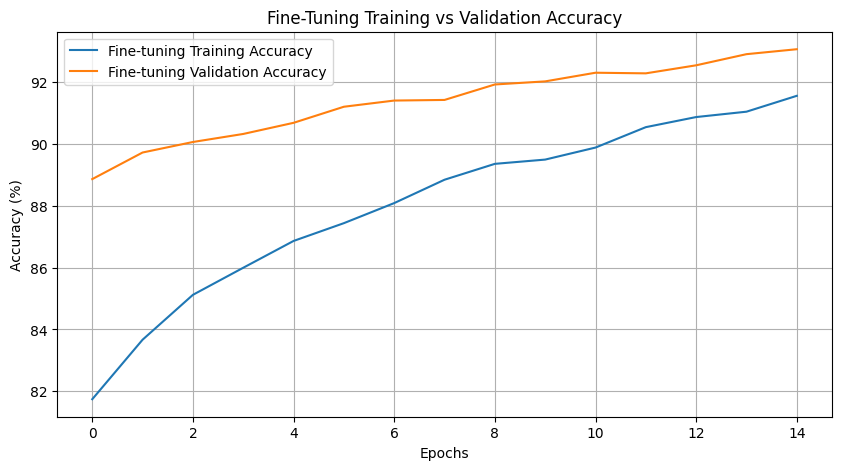

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    finetune_train_accuracies,
    label="Fine-tuning Training Accuracy"
)

plt.plot(
    finetune_val_accuracies,
    label="Fine-tuning Validation Accuracy"
)

plt.title("Fine-Tuning Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid(True)
plt.show()

##Test Loss and Accuracy

In [ ]:

model.eval()

test_loss = 0.0
correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_loss = test_loss / total
test_accuracy = 100 * correct / total

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 2), "%")

Test Loss: 0.2286
Test Accuracy: 92.33 %


##Confusion Matrix

<Figure size 1000x1000 with 0 Axes>

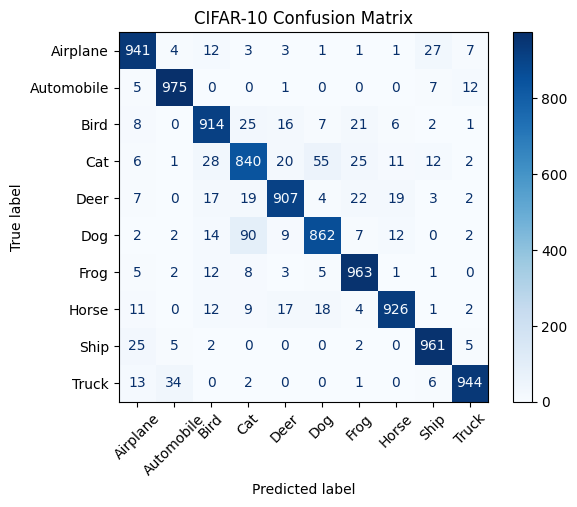

In [ ]:
# ==========================================
# 31. CONFUSION MATRIX
# ==========================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap='Blues',
    xticks_rotation=45,
    values_format='d'
)

plt.title("CIFAR-10 Confusion Matrix")
plt.show()

##PER-CLASS ACCURACY

In [ ]:
# ==========================================
# 32. PER-CLASS ACCURACY
# ==========================================

class_correct = cm.diagonal()
class_total = cm.sum(axis=1)

class_accuracy = (
    class_correct / class_total
) * 100

for i in range(len(class_names)):

    print(
        f"{class_names[i]}: "
        f"{class_accuracy[i]:.2f}%"
    )

Airplane: 94.10%
Automobile: 97.50%
Bird: 91.40%
Cat: 84.00%
Deer: 90.70%
Dog: 86.20%
Frog: 96.30%
Horse: 92.60%
Ship: 96.10%
Truck: 94.40%



# 33. CLASSIFICATION REPORT


In [ ]:


from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

    Airplane       0.92      0.94      0.93      1000
  Automobile       0.95      0.97      0.96      1000
        Bird       0.90      0.91      0.91      1000
         Cat       0.84      0.84      0.84      1000
        Deer       0.93      0.91      0.92      1000
         Dog       0.91      0.86      0.88      1000
        Frog       0.92      0.96      0.94      1000
       Horse       0.95      0.93      0.94      1000
        Ship       0.94      0.96      0.95      1000
       Truck       0.97      0.94      0.95      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



In [ ]:
# ==========================================
# 34. HARDEST CLASSES
# ==========================================

sorted_classes = sorted(
    zip(class_names, class_accuracy),
    key=lambda x: x[1]
)

print("Hardest classes to classify:\n")

for name, accuracy in sorted_classes[:3]:

    print(f"{name}: {accuracy:.2f}% accuracy")

Hardest classes to classify:

Cat: 84.00% accuracy
Dog: 86.20% accuracy
Deer: 90.70% accuracy


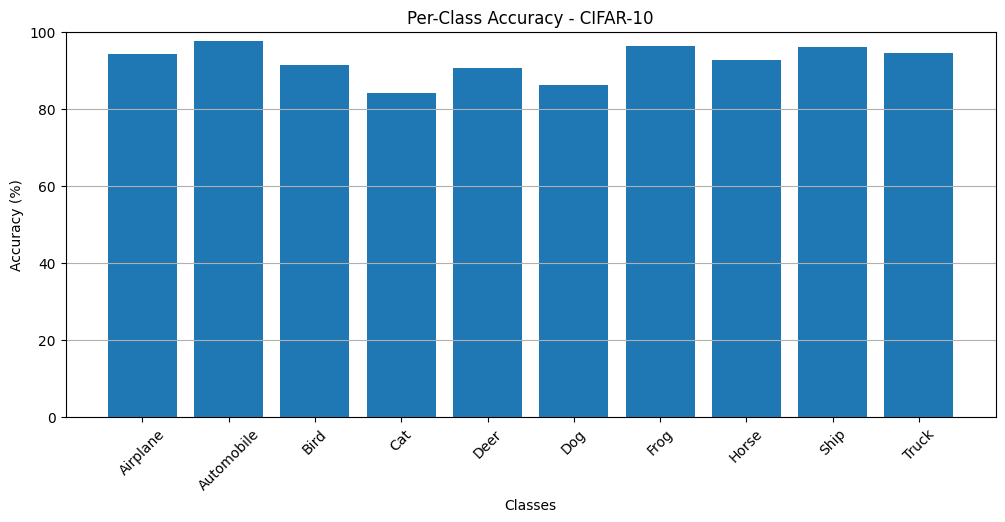

In [ ]:
plt.figure(figsize=(12, 5))

plt.bar(class_names, class_accuracy)

plt.title("Per-Class Accuracy - CIFAR-10")
plt.xlabel("Classes")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.grid(axis='y')

plt.show()

In [ ]:
# ==========================================
# 36. FEATURE EXTRACTION VS FINE-TUNING
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    val_accuracies,
    label="Feature Extraction"
)

plt.plot(
    finetune_val_accuracies,
    label="Fine-Tuning"
)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid(True)
plt.show()

SyntaxError: invalid syntax (2623240671.py, line 23)